# Week 4 — Baseline Model
- Train a Linear Regression as the first model.
- Evaluate using R² on the test set.
  - in DS best practices: also says to "Report R², MAPE, MdAPE, and MAE together — no single metric tells the whole story"
- Record baseline results.

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
# Linear Model
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge


# Pipeline & Feature Processing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


# Validation
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

In [57]:
filtered_cleaned = pd.read_csv("/content/drive/MyDrive/IDX Data Science/filtered_cleaned.csv")
print(f"Current number of rows: {len(filtered_cleaned)}")

/tmp/ipykernel_1303/2430598771.py:1: DtypeWarning: Columns (0,1,4,64,74,79,81,82,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_cleaned = pd.read_csv("/content/drive/MyDrive/IDX Data Science/filtered_cleaned.csv")


Current number of rows: 303800


Preprocessing continued: catching up from last week
- train/validation/test split
- removing outliers (training set)
- normalizing numeric features
- encoding categorical columns

In [6]:
# check filedates to see when are most recent 2 months of data
filtered_cleaned['FileDate'].sort_values(ascending=False).unique()

array(['2026-04-01', '2026-03-01', '2026-02-01', '2026-01-01',
       '2025-12-01', '2025-11-01', '2025-10-01', '2025-09-01',
       '2025-08-01', '2025-07-01', '2025-06-01', '2025-05-01',
       '2025-04-01', '2025-03-01', '2025-02-01', '2025-01-01',
       '2024-12-01', '2024-11-01', '2024-10-01', '2024-09-01',
       '2024-08-01', '2024-07-01', '2024-06-01', '2024-05-01',
       '2024-04-01', '2024-03-01', '2024-02-01', '2024-01-01'],
      dtype=object)

In [7]:
test = filtered_cleaned[filtered_cleaned['FileDate'] == '2026-04-01']
print(f"Test set size: {len(test)}")
validation = filtered_cleaned[filtered_cleaned['FileDate'] == '2026-03-01']
print(f"Validation set size: {len(validation)}")
train = filtered_cleaned[filtered_cleaned['FileDate'] < '2026-03-01']
print(f"Train set size: {len(train)}")

print(f"Total Rows Check: {len(test) + len(validation) + len(train)}")

Test set size: 12225
Validation set size: 11368
Train set size: 280207
Total Rows Check: 303800


In [8]:
# set outlier cutoffs based on the training set
lower_bound = train['ClosePrice'].quantile(0.05)
upper_bound = train['ClosePrice'].quantile(0.995)
print(f"Lower bound: {lower_bound}")
print(f"Upper bound: {upper_bound}")

Lower bound: 365000.0
Upper bound: 8300000.0


In [74]:
key_feature_cols = ['LivingArea', 'BedroomsTotal',
                    'BathroomsTotalInteger', 'LotSizeSquareFeet',
                    'YearBuilt', 'Latitude', 'Longitude']
# filter based on upper and lower bounds from training
train = train[(train['ClosePrice'] > lower_bound) & (train['ClosePrice'] < upper_bound)]
validation = validation[(validation['ClosePrice'] > lower_bound) & (validation['ClosePrice'] < upper_bound)]
test = test[(test['ClosePrice'] > lower_bound) & (test['ClosePrice'] < upper_bound)]

#keep feature columns
train = train[key_feature_cols + ['ClosePrice']]
validation = validation[key_feature_cols + ['ClosePrice']]
test = test[key_feature_cols + ['ClosePrice']]

In [75]:
# Row counts after removing outliers
print(f"Test set size: {len(test)}")
print(f"Validation set size: {len(validation)}")
print(f"Train set size: {len(train)}")

print(f"Total Rows: {len(test) + len(validation) + len(train)}")

Test set size: 11519
Validation set size: 10681
Train set size: 264737
Total Rows: 286937


In [76]:
# separate X's and Y for data sets
Y_train = train['ClosePrice']
X_train = train[key_feature_cols]

Y_val = validation['ClosePrice']
X_val = validation[key_feature_cols]

Y_test = test['ClosePrice']
X_test = test[key_feature_cols]

# Building The Regression Model

In [77]:
# processing for numeric columns: Impute missing values with median, then scale
num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, key_feature_cols),
        # ("cat", cat_pipeline, cat_cols), # Add target encoder for categoricals here when using

    ]
)

# using both OLS and Ridge (regularized) for comparison

ols_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression()),
    ]
)

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

In [78]:
# MdAPE
def median_absolute_percentage_error(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100
# function to evaluate different errors (R^2, MAE, MAPE, MdAPE)
def evaluate_predictions(y_true, y_pred, split_name="Validation"):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100  # Convert ratio to %
    mdape = median_absolute_percentage_error(y_true, y_pred)

    print(f"--- {split_name} Evaluation Metrics ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : ${mae:,.2f}")
    print(f"MAPE     : {mape:.2f}%")
    print(f"MdAPE    : {mdape:.2f}%\n")

## OLS Model

In [79]:
# Fitting on training data
ols_pipeline.fit(X_train, Y_train)

# Predict on Validation Set
ols_val_preds = ols_pipeline.predict(X_val)
evaluate_predictions(Y_val, ols_val_preds, split_name="Validation Set - OLS")

--- Validation Set - OLS Evaluation Metrics ---
R² Score : 0.4401
MAE      : $458,624.12
MAPE     : 42.51%
MdAPE    : 30.38%



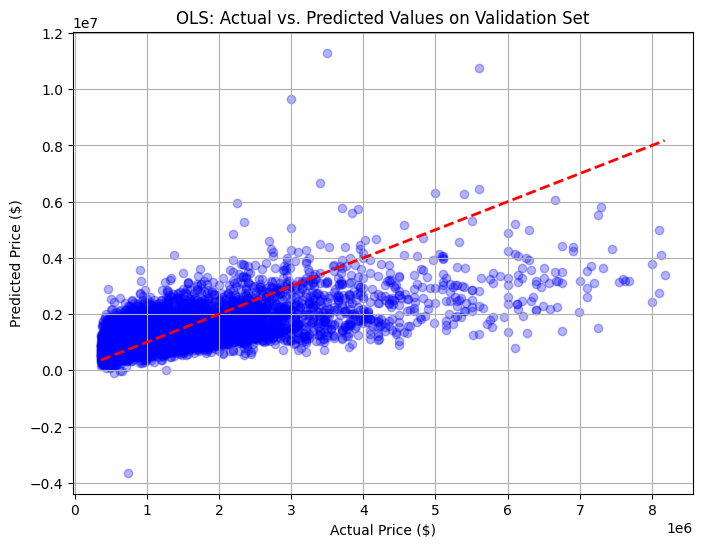

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(Y_val, ols_val_preds, alpha=0.3, color="blue")
plt.plot([Y_val.min(), Y_val.max()], [Y_val.min(), Y_val.max()], "r--", lw=2)
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("OLS: Actual vs. Predicted Values on Validation Set")
plt.grid(True)
plt.show()

In [80]:
# Testing on combined data X_train and X_val
X_train_val = pd.concat([X_train, X_val], axis=0)
Y_train_val = pd.concat([Y_train, Y_val], axis=0)

ols_pipeline.fit(X_train_val, Y_train_val)

# Predict on held-out test set
ols_test_preds = ols_pipeline.predict(X_test)
evaluate_predictions(Y_test, ols_test_preds, split_name="Test Set - OLS")

--- Test Set - OLS Evaluation Metrics ---
R² Score : 0.4630
MAE      : $461,747.14
MAPE     : 41.75%
MdAPE    : 29.64%



## Ridge Model

In [81]:
# Fitting on training data
ridge_pipeline.fit(X_train, Y_train)

# Predict on Validation Set
ridge_val_preds = ridge_pipeline.predict(X_val)
evaluate_predictions(Y_val, ridge_val_preds, split_name="Validation Set - Ridge")

--- Validation Set - Ridge Evaluation Metrics ---
R² Score : 0.4401
MAE      : $458,624.01
MAPE     : 42.51%
MdAPE    : 30.38%



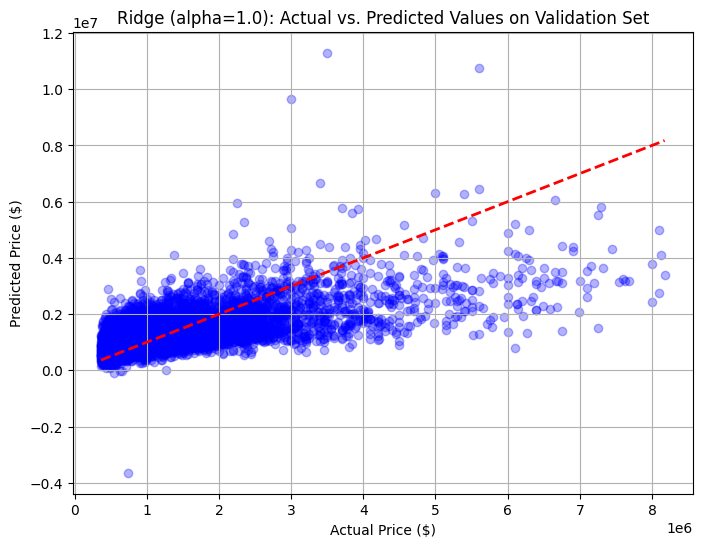

In [88]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_val, ridge_val_preds, alpha=0.3, color="blue")
plt.plot([Y_val.min(), Y_val.max()], [Y_val.min(), Y_val.max()], "r--", lw=2)
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Ridge (alpha=1.0): Actual vs. Predicted Values on Validation Set")
plt.grid(True)
plt.show()

In [82]:
# Testing on combined data X_train and X_val
X_train_val = pd.concat([X_train, X_val], axis=0)
Y_train_val = pd.concat([Y_train, Y_val], axis=0)

ols_pipeline.fit(X_train_val, Y_train_val)

# Predict on held-out test set
ols_test_preds = ols_pipeline.predict(X_test)
evaluate_predictions(Y_test, ols_test_preds, split_name="Test Set - Ridge")

--- Test Set Evaluation Metrics ---
R² Score : 0.4630
MAE      : $461,747.14
MAPE     : 41.75%
MdAPE    : 29.64%



### Ridge pt. 2
- looking for more optimal alphas

In [83]:
# GEMINI-ASSISTED
alpha_candidates = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

tuning_results = []

for alpha in alpha_candidates:
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=alpha)),
    ])

    # Fit strictly on training set
    model_pipeline.fit(X_train, Y_train)

    # Predict on validation set
    val_preds = model_pipeline.predict(X_val)

    # validation metrics
    r2 = r2_score(Y_val, val_preds)
    mae = mean_absolute_error(Y_val, val_preds)
    mape = mean_absolute_percentage_error(Y_val, val_preds) * 100
    mdape = np.median(np.abs((Y_val - val_preds) / Y_val)) * 100

    tuning_results.append({
        "alpha": alpha,
        "Validation R²": r2,
        "MAE ($)": mae,
        "MAPE (%)": mape,
        "MdAPE (%)": mdape,
    })

# Convert to DataFrame to select the best hyperparameter
results_df = pd.DataFrame(tuning_results)
print(results_df.to_string(index=False))

# 2. Select optimal alpha based on primary metric (e.g., lowest MdAPE or MAE)
best_alpha = results_df.loc[results_df["MdAPE (%)"].idxmin()]["alpha"]
print(f"\nOptimal Alpha selected: {best_alpha}")

  alpha  Validation R²       MAE ($)  MAPE (%)  MdAPE (%)
   0.01       0.440078 458624.119552 42.505859  30.379623
   0.10       0.440078 458624.109746 42.505859  30.379676
   1.00       0.440079 458624.011696 42.505859  30.380211
  10.00       0.440080 458623.031315 42.505857  30.380600
 100.00       0.440096 458613.374962 42.505845  30.359372
1000.00       0.440241 458529.570559 42.507427  30.398735

Optimal Alpha selected: 100.0


In [84]:
ridge_pipeline.set_params(model__alpha=best_alpha)

# Now the pipeline uses best_alpha
ridge_pipeline.fit(X_train_val, Y_train_val)
ridge_optim_test_preds = ridge_pipeline.predict(X_test)
evaluate_predictions(Y_test, ridge_optim_test_preds, split_name="Testing - Ridge with Alpha = 100")

--- Testing - Ridge with Alpha = 100 Evaluation Metrics ---
R² Score : 0.4629
MAE      : $461,744.04
MAPE     : 41.75%
MdAPE    : 29.63%



## Discussion of Results

Overall, the linear regression models (OLS, Ridge with different alphas) tended to perfrom pretty poorly, with MdAPEs of around 30%. While I removed outliers fit on the training data between the 0.5th and 99.5th percentiles, from the scatterplots it still seems like the models are still influenced by higher values of Close Price (which we may be able to infer from the fluctuating MAEs). The MAPEs were also on the higher end at around 40%, which supports the weak robustness of the linear regression model since the mean is more sensitive to outliers than the median.